![display relevant image here](path/url/to/image)
- Banner/header image

# Title
- Relevant to Data and Business Context

## Overview
- BLUF (Bottom Line Up Front)
- One paragraph summary of final model performance and business implications
- Frame your 'story'

## Business Understanding

1. Begin by thoroughly analyzing the business context of FinTech Innovations' loan approval process. Write a short summary that:
- Describes the current manual process and its limitations
- Identifies key stakeholders and their needs
- Explains the implications of different types of model errors
- Justifies your choice between classification and regression approaches

2. Define your modeling goals and success criteria:
- Select appropriate evaluation metrics based on business impact
- You must use at least two different metrics
- Consider creating custom metric
- Establish baseline performance targets
- Document your reasoning for each choice


## Data Understanding
3. Conduct comprehensive exploratory data analysis:
- Describe basic data characteristics
- Examine distributions of all features and target variables
- Investigate relationships between features
- Create visualizations to help aid in EDA
- Document potential data quality issues and their implications

4. Develop feature understanding:
- Categorize features by type (numerical, categorical, ordinal)
- Identify features requiring special preprocessing
- Document missing value patterns and their potential meanings
- Note potential feature engineering opportunities



## 1. Business Understanding

### 1.1 Business Problem

FinTech Innovations aims to improve the loan approval process by using machine learning to support consistent, efficient, and data-driven lending decisions.

The existing manual process can result in inconsistent decisions, delayed approvals, and financial losses.

### 1.2 Project Objective

The objective is to develop and evaluate classification models that predict historical loan approval decisions using applicant information.

The model will support loan officers in making decisions. Historical approval predictions will not automatically be treated as predictions of actual loan defaults.

### 1.3 Business Costs

The business faces two major financial risks:

- Approving a loan that subsequently defaults: $50,000 average loss.
- Rejecting a creditworthy applicant: $8,000 average lost profit.

Approving a defaulting borrower is 6.25 times more costly than rejecting a creditworthy applicant.

### 1.4 Evaluation Metrics

The following metrics will be considered:

- Precision: Measures how many predicted approvals are correct.
- Recall: Measures how many actual approvals are identified.
- F1-score: Balances precision and recall.
- ROC-AUC: Measures the model's ability to distinguish the classes.
- Confusion Matrix: Shows correct and incorrect predictions.

Business costs will also be evaluated, subject to the availability of valid repayment or default outcomes.

### 1.5 Stakeholders

- Loan officers: Need interpretable predictions.
- Management: Wants reduced financial losses and faster processing.
- Applicants: Need fair and consistent decisions.


In [2]:
# Imports

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, chi2_contingency
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, classification_report, precision_recall_curve, brier_score_loss)
from sklearn.inspection import permutation_importance
sns.set_theme(style='whitegrid')
RANDOM_STATE=42
print('Imports successful')

Imports successful


In [8]:
# EDA Code Here - Create New Cells As Needed

# Load the dataset
df = pd.read_csv("financial_loan_data.csv")

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display first five rows
display(df.head())

# Check data types
display(df.dtypes.to_frame("dtype"))

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("Duplicate Rows:", df.duplicated().sum())

# Create a copy for EDA
eda = df.copy()



Dataset Shape: (20000, 35)


,Age,AnnualIncome,CreditScore,EmploymentStatus,EducationLevel,Experience,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,...,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,LoanApproved,RiskScore
0,45,"$39,948.00",617,Employed,Master,22,13152,48,Married,2,...,3329.000000,0.724972,11,126928,0.199652,0.227590,419.805992,0.181077,0,49.0
1,38,"$39,709.00",628,Employed,Associate,15,26045,48,Single,1,...,3309.083333,0.935132,3,43609,0.207045,0.201077,794.054238,0.389852,0,52.0
2,47,"$40,724.00",570,Employed,Bachelor,26,17627,36,NaN,2,...,3393.666667,0.872241,6,5205,0.217627,0.212548,666.406688,0.462157,0,52.0
3,58,"$69,084.00",545,Employed,High School,34,37898,96,Single,1,...,5757.000000,0.896155,5,99452,0.300398,0.300911,1047.506980,0.313098,0,54.0
4,37,"$103,264.00",594,Employed,Associate,17,9184,36,Married,1,...,8605.333333,0.941369,5,227019,0.197184,0.175990,330.179140,0.070210,1,36.0


,dtype
Age,int64
AnnualIncome,object
CreditScore,int64
EmploymentStatus,object
EducationLevel,object
Experience,int64
LoanAmount,int64
LoanDuration,int64
MaritalStatus,object
NumberOfDependents,int64


Missing Values:
Age                              0
AnnualIncome                     0
CreditScore                      0
EmploymentStatus                 0
EducationLevel                 901
Experience                       0
LoanAmount                       0
LoanDuration                     0
MaritalStatus                 1331
NumberOfDependents               0
HomeOwnershipStatus              0
MonthlyDebtPayments              0
CreditCardUtilizationRate        0
NumberOfOpenCreditLines          0
NumberOfCreditInquiries          0
DebtToIncomeRatio                0
BankruptcyHistory                0
LoanPurpose                      0
PreviousLoanDefaults             0
PaymentHistory                   0
LengthOfCreditHistory            0
SavingsAccountBalance          572
CheckingAccountBalance           0
TotalAssets                      0
TotalLiabilities                 0
MonthlyIncome                    0
UtilityBillsPaymentHistory       0
JobTenure                        0
NetW

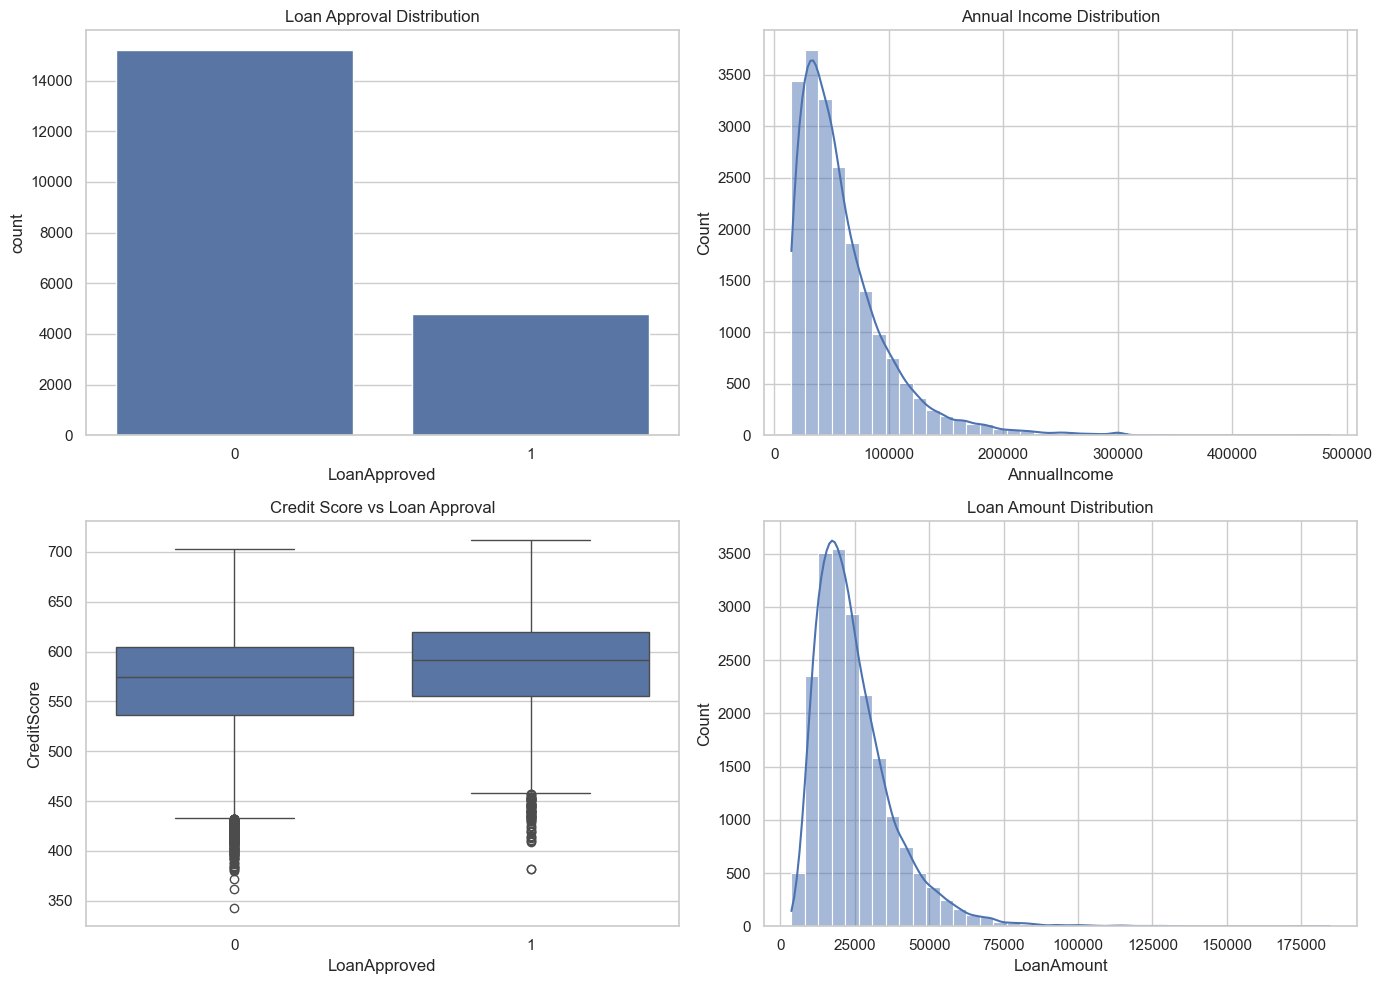

In [28]:

# Step 1: Create a copy for exploratory analysis
# Keep the original dataset unchanged
eda = df.copy()

# Step 2: Clean AnnualIncome for visualization
# Remove currency symbols and commas
eda["AnnualIncome"] = pd.to_numeric(
    eda["AnnualIncome"].astype(str)
    .str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

# Step 3: Create four EDA visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Chart 1: Loan approval distribution
sns.countplot(
    data=eda,
    x="LoanApproved",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Loan Approval Distribution")

# Chart 2: Annual income distribution
sns.histplot(
    data=eda,
    x="AnnualIncome",
    bins=40,
    kde=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Annual Income Distribution")

# Chart 3: Credit score by approval status
sns.boxplot(
    data=eda,
    x="LoanApproved",
    y="CreditScore",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Credit Score vs Loan Approval")

# Chart 4: Loan amount distribution
sns.histplot(
    data=eda,
    x="LoanAmount",
    bins=40,
    kde=True,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Loan Amount Distribution")

plt.tight_layout()
plt.show()


## Data Preparation
5. Design your preprocessing strategy:
- Create separate preprocessing flows for different feature types
- Must utilize ColumnTransformer and Pipeline
- Consider using FeatureUnion as well
- Handle missing values appropriately for each feature
- Handle Categorical and Ordinal data appropriately
- Scale numeric values if model requires it (linear model)
- Document your reasoning for each preprocessing decision



In [9]:
# Data Prep Code Here - Create New Cells As Needed

# X: All available predictors except the target
X = df.drop(columns=["LoanApproved"])

# Xf: Final features used for modeling
# Remove RiskScore because it may cause data leakage
Xf = X.drop(columns=["RiskScore"])

# y: Target variable
y = df["LoanApproved"]
#Split the dataset into training and testing sets
# 80% for training and 20% for testing
X_train,X_test,y_train,y_test = train_test_split(Xf,y,test_size=0.2,random_state=42,stratify=y)

# Step 5: Verify the results
print("Features:", Xf.shape)
print("Target:", y.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Features: (20000, 33)
Target: (20000,)
Training features: (16000, 33)
Testing features: (4000, 33)
Training target: (16000,)
Testing target: (4000,)


In [10]:

# Step 1: Import preprocessing tools
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer
import pandas as pd
import numpy as np

# Step 2: Create a function to clean AnnualIncome
# Remove dollar signs and commas, then convert to numbers
def clean_income(data):
    data = data.copy()
    data["AnnualIncome"] = pd.to_numeric(
        data["AnnualIncome"].astype(str)
        .str.replace(r"[$,]", "", regex=True),
        errors="coerce"
    )
    return data

# Step 3: Create an income-cleaning transformer
# This allows income cleaning to run inside the pipeline
income_transformer = FunctionTransformer(
    clean_income,
    validate=False
)

# Step 4: Identify numerical and categorical columns
# Use the training data to determine feature types
X_train_clean = clean_income(X_train)

numerical_features = X_train_clean.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train_clean.select_dtypes(
    exclude=np.number
).columns.tolist()

# Step 5: Create the numerical preprocessing pipeline
# Median imputation fills missing numerical values
# StandardScaler standardizes numerical features
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Step 6: Create the categorical preprocessing pipeline
# Most frequent imputation fills missing categories
# OneHotEncoder converts categories into numerical columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Step 7: Combine both pipelines using ColumnTransformer
# Apply the appropriate preprocessing to each feature type
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Step 8: Combine income cleaning and preprocessing
# This pipeline will later be connected to each model
full_preprocessor = Pipeline([
    ("income_cleaner", income_transformer),
    ("preprocessor", preprocessor)
])

# Step 9: Verify the preprocessing configuration
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("Preprocessing pipeline created successfully!")


Numerical features: ['Age', 'AnnualIncome', 'CreditScore', 'Experience', 'LoanAmount', 'LoanDuration', 'NumberOfDependents', 'MonthlyDebtPayments', 'CreditCardUtilizationRate', 'NumberOfOpenCreditLines', 'NumberOfCreditInquiries', 'DebtToIncomeRatio', 'PreviousLoanDefaults', 'PaymentHistory', 'LengthOfCreditHistory', 'SavingsAccountBalance', 'CheckingAccountBalance', 'TotalAssets', 'TotalLiabilities', 'MonthlyIncome', 'UtilityBillsPaymentHistory', 'JobTenure', 'NetWorth', 'BaseInterestRate', 'InterestRate', 'MonthlyLoanPayment', 'TotalDebtToIncomeRatio']
Categorical features: ['EmploymentStatus', 'EducationLevel', 'MaritalStatus', 'HomeOwnershipStatus', 'BankruptcyHistory', 'LoanPurpose']
Preprocessing pipeline created successfully!


## Modeling
6. Implement your modeling approach:
- Choose appropriate model algorithms based on your problem definition
- Set up validation strategy with chosen metrics
- Use a train test split and cross validation
- Create complete pipeline including any preprocessing and model
- Document your reasoning for each modeling decision

7. Optimize your model:
- Define parameter grid based on your understanding of the algorithms
- Implement GridSearchCV and/or RandomizedSearchCV with chosen metrics
- Consider tuning preprocessing steps
- Track and document the impact of different parameter combinations
- Consider the trade-offs between different model configurations

NOTE: Be mindful of time considerations - showcase “how to tune” 


In [11]:
#  Modeling Code Here - Create New Cells as Needed

# Step 1: Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# Step 2: Define the five classification algorithms
# Each model will predict LoanApproved (0 = Denied, 1 = Approved)
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100,
        random_state=42
    )
}

# Step 3: Verify the models
print("Number of models:", len(models))
print("Models:", list(models.keys()))


Number of models: 5
Models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Extra Trees', 'Gradient Boosting']


In [ ]:

# Step 3: Import cross-validation tools
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
import pandas as pd

# Step 4: Define 5-fold stratified cross-validation
# This preserves the proportion of approved and denied loans
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Step 3: Define the evaluation metrics
# We use multiple metrics because our dataset is imbalanced
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Step 5: Create an empty list to store model results
results = []

# Step 6: Train and evaluate each model
# Each model uses the preprocessing pipeline
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", full_preprocessor),
        ("classifier", model)
    ])

    # Evaluate using five training folds
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    # Store the average evaluation scores
    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

    print(name, "completed")

# Step 7: Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Step 8: Sort models by ROC-AUC
results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

# Step 9: Display the existing model comparison results
display(results_df)

# Step 10: Identify the ROC-AUC column
print("Available columns:", results_df.columns.tolist())


# Step 11: Display the comparison table
display(results_df.round(4))


Logistic Regression completed
Decision Tree completed
Random Forest completed
Extra Trees completed
Gradient Boosting completed


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.964687,0.932070,0.919189,0.925578,0.994624
4,Gradient Boosting,0.951250,0.908325,0.885455,0.896709,0.989970
3,Extra Trees,0.924063,0.926688,0.741105,0.823496,0.979527
2,Random Forest,0.927500,0.888530,0.796541,0.839985,0.976480
1,Decision Tree,0.898375,0.800302,0.765945,0.782565,0.887910


Available columns: ['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9647,0.9321,0.9192,0.9256,0.9946
4,Gradient Boosting,0.9512,0.9083,0.8855,0.8967,0.9900
3,Extra Trees,0.9241,0.9267,0.7411,0.8235,0.9795
2,Random Forest,0.9275,0.8885,0.7965,0.8400,0.9765
1,Decision Tree,0.8984,0.8003,0.7659,0.7826,0.8879


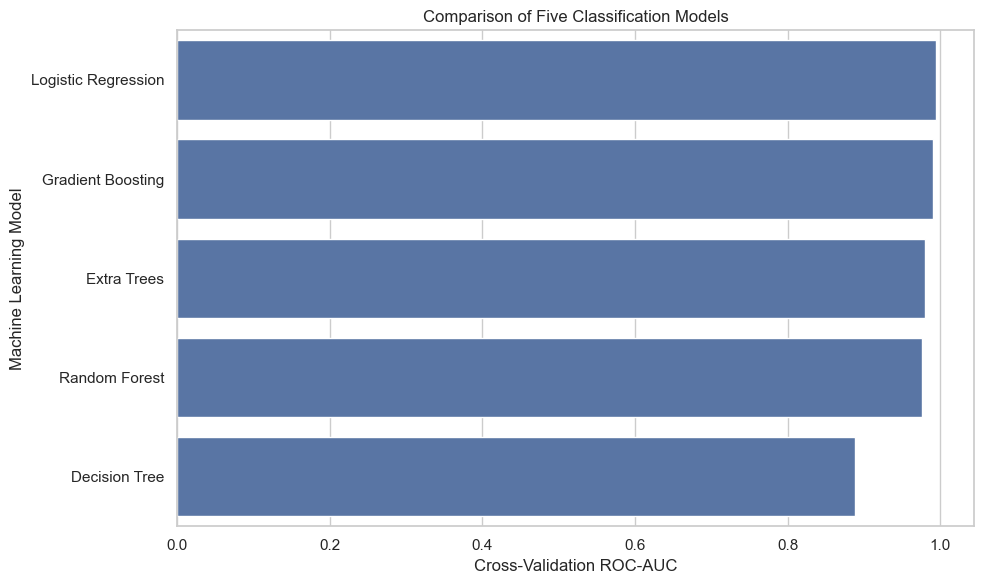

In [ ]:

# Step 13: Identify the ROC-AUC column
roc_col = next(
    col for col in results_df.columns
    if "roc" in col.lower() and "auc" in col.lower()
)

# Step 14: Sort models by ROC-AUC
comparison = results_df.sort_values(
    by=roc_col,
    ascending=False
)

# Step 15: Visualize model performance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison,
    x=roc_col,
    y="Model"
)

plt.title("Comparison of Five Classification Models")
plt.xlabel("Cross-Validation ROC-AUC")
plt.ylabel("Machine Learning Model")
plt.tight_layout()
plt.show()


In [ ]:

# Step 16: Import RandomizedSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone


# Step 17: Identify the best model from our comparison results
# Select the model with the highest cross-validation ROC-AUC
best_model_name = results_df.loc[
    results_df["ROC-AUC"].idxmax(), "Model"
]

# Step 18: Retrieve the selected model from our models dictionary
best_model = models[best_model_name]

# Step 3: Display the selected model
print("Best Model:", best_model_name)
print("Model Algorithm:", best_model)


# Step 19: Define hyperparameter options for each model
# These parameters control model complexity and performance

param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__class_weight": [None, "balanced"]
    },

    "Decision Tree": {
        "classifier__max_depth": [3, 5, 10, 15, None],
        "classifier__min_samples_split": [2, 5, 10, 20],
        "classifier__min_samples_leaf": [1, 2, 5, 10]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [5, 10, 20, None],
        "classifier__min_samples_leaf": [1, 2, 5],
        "classifier__max_features": ["sqrt", "log2"]
    },

    "Extra Trees": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [5, 10, 20, None],
        "classifier__min_samples_leaf": [1, 2, 5],
        "classifier__max_features": ["sqrt", "log2"]
    },

    "Gradient Boosting": {
        "classifier__max_iter": [100, 150, 200],
        "classifier__learning_rate": [0.01, 0.05, 0.1],
        "classifier__max_leaf_nodes": [15, 31, 63],
        "classifier__l2_regularization": [0, 0.1, 1.0]
    }
}

# Step 20: Select the search space for our best model
param_distributions = param_grids[best_model_name]

print("Model selected:", best_model_name)
print("Parameters to tune:", param_distributions)


Best Model: Logistic Regression
Model Algorithm: LogisticRegression(max_iter=1000, random_state=42)
Model selected: Logistic Regression
Parameters to tune: {'classifier__C': [0.01, 0.1, 1, 10, 100], 'classifier__class_weight': [None, 'balanced']}


In [ ]:

# Step 21: Create a pipeline for the selected model
# Combine preprocessing with Logistic Regression
tuning_pipeline = Pipeline([
    ("preprocessing", clone(full_preprocessor)),
    ("classifier", clone(best_model))
])

# Step 22: Configure RandomizedSearchCV
# Test parameter combinations using 5-fold cross-validation
# ROC-AUC is our optimization metric
random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Step 23: Train and tune using training data only
random_search.fit(X_train, y_train)

# Step 24: Display the best parameters and performance
print("Best Parameters:", random_search.best_params_)
print("Best ROC-AUC:", round(random_search.best_score_, 4))

# Step 25: Save the optimized model
tuned_model = random_search.best_estimator_


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'classifier__class_weight': None, 'classifier__C': 100}
Best ROC-AUC: 0.9947


In [31]:

# Step 26: Retrieve Logistic Regression's original CV score
before_tuning = results_df.loc[
    results_df["Model"] == best_model_name,
    "ROC-AUC"
].iloc[0]

# Step 2: Retrieve the tuned model's CV score
after_tuning = random_search.best_score_

# Step 27: Compare the results
tuning_comparison = pd.DataFrame({
    "Model": ["Before Tuning", "After Tuning"],
    "ROC-AUC": [before_tuning, after_tuning]
})

display(tuning_comparison.round(6))

# Step 28: Calculate improvement
improvement = after_tuning - before_tuning

print(f"ROC-AUC Improvement: {improvement:.6f}")


,Model,ROC-AUC
0,Before Tuning,0.994624
1,After Tuning,0.994703


ROC-AUC Improvement: 0.000079


In [ ]:

# Step 29: Generate predictions using the tuned model
# Predict whether each loan application is approved or denied
y_pred = tuned_model.predict(X_test)

# Step 30: Generate predicted probabilities
# [:, 1] selects the probability of LoanApproved = 1
y_prob = tuned_model.predict_proba(X_test)[:, 1]

# Step 31: Verify the predictions
print("Predicted classes:", y_pred.shape)
print("Predicted probabilities:", y_prob.shape)

# Step 32: Display the first five probabilities
print("First five probabilities:", y_prob[:5])


Predicted classes: (4000,)
Predicted probabilities: (4000,)
First five probabilities: [6.40683396e-28 3.33038354e-01 9.99999999e-01 1.69131030e-26
 3.62001131e-07]


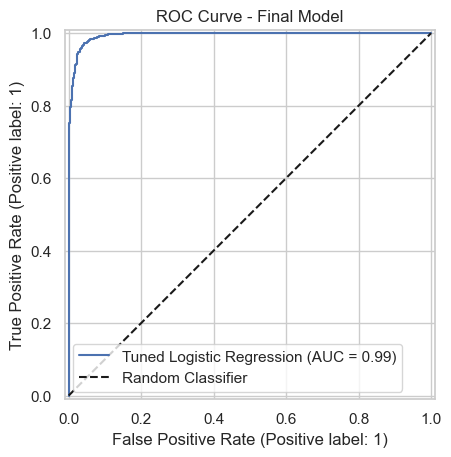

In [ ]:

# Step 33: Import ROC curve tools
from sklearn.metrics import RocCurveDisplay

# Step 34: Plot the ROC curve
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Tuned Logistic Regression"
)

plt.title("ROC Curve - Final Model")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.legend()
plt.show()


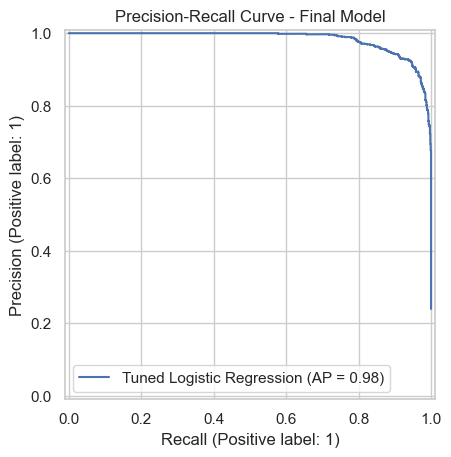

In [ ]:

# Step 35: Import precision-recall curve tools
from sklearn.metrics import PrecisionRecallDisplay

# Step 36: Plot the precision-recall curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob,
    name="Tuned Logistic Regression"
)

plt.title("Precision-Recall Curve - Final Model")
plt.show()


In [ ]:

# Step 37: Import confusion matrix
from sklearn.metrics import confusion_matrix

# Step 38: Calculate the confusion matrix
# Labels: 0 = Denied, 1 = Approved
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
).ravel()

# Step 39: Define business costs
cost_false_approval = 50000
cost_false_denial = 8000

# Step 40: Calculate illustrative costs
# FP: Model approves an application historically denied
# FN: Model denies an application historically approved
fp_cost = fp * cost_false_approval
fn_cost = fn * cost_false_denial

# Step 41: Calculate total illustrative cost
total_cost = fp_cost + fn_cost

# Step 42: Display the results
print("False Positives:", fp)
print("False Negatives:", fn)

print(f"False Positive Cost: ${fp_cost:,.2f}")
print(f"False Negative Cost: ${fn_cost:,.2f}")
print(f"Total Illustrative Cost: ${total_cost:,.2f}")


False Positives: 67
False Negatives: 71
False Positive Cost: $3,350,000.00
False Negative Cost: $568,000.00
Total Illustrative Cost: $3,918,000.00


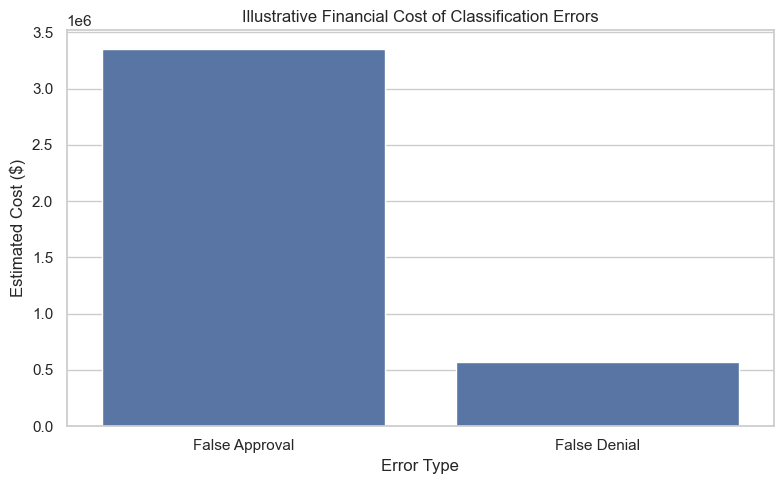

In [ ]:

# Step 43: Create a financial cost comparison chart
costs = pd.DataFrame({
    "Error Type": [
        "False Approval",
        "False Denial"
    ],
    "Illustrative Cost": [
        fp_cost,
        fn_cost
    ]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=costs,
    x="Error Type",
    y="Illustrative Cost"
)

plt.title("Illustrative Financial Cost of Classification Errors")
plt.xlabel("Error Type")
plt.ylabel("Estimated Cost ($)")
plt.tight_layout()
plt.show()


In [ ]:

# Step 44: Extract the fitted preprocessing pipeline
fitted_preprocessor = tuned_model.named_steps[
    "preprocessing"
].named_steps["preprocessor"]

# Step 46: Extract the trained Logistic Regression model
classifier = tuned_model.named_steps["classifier"]

# Step 47: Retrieve transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Step 448: Extract model coefficients
coefficients = classifier.coef_[0]

# Step 49: Create a feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute Importance": np.abs(coefficients)
})

# Step 50: Sort by absolute coefficient magnitude
feature_importance = feature_importance.sort_values(
    "Absolute Importance",
    ascending=False
)

# Step 51: Display the top 15 features
display(feature_importance.head(15))


,Feature,Coefficient,Absolute Importance
26,num__TotalDebtToIncomeRatio,-10.537470,10.537470
44,cat__BankruptcyHistory_Yes,-6.458242,6.458242
24,num__InterestRate,-6.006335,6.006335
19,num__MonthlyIncome,5.509572,5.509572
29,cat__EmploymentStatus_Unemployed,-4.271602,4.271602
33,cat__EducationLevel_High School,-3.938474,3.938474
22,num__NetWorth,3.156408,3.156408
4,num__LoanAmount,-2.480196,2.480196
30,cat__EducationLevel_Associate,-2.463111,2.463111
2,num__CreditScore,-2.386099,2.386099


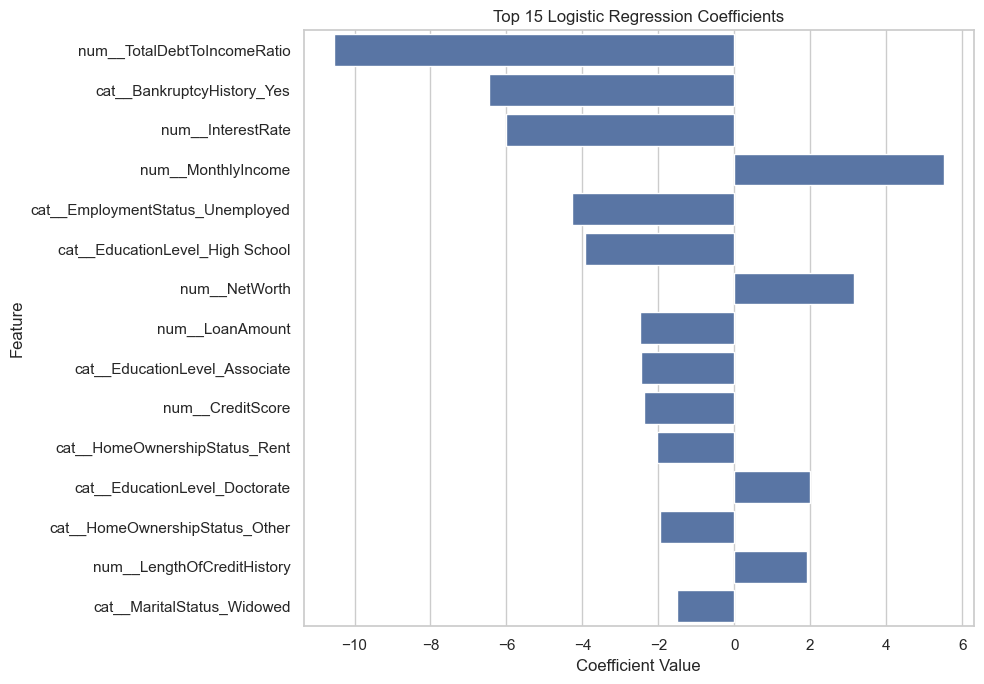

In [25]:

# Select the top 15 features
top_features = feature_importance.head(15)

# Create a horizontal bar chart
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature"
)

plt.title("Top 15 Logistic Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## Evaluation and Conclusion
8. Conduct thorough evaluation of final model:
- Assess models test data performance using your defined metrics
- Analyze performance across different data segments
- Identify potential biases or limitations
- Visualize model performance
    - Classification: Confusion Matrix/ROC-AUC
    - Regression: Scatter Plot (Predicted vs. Actual values)

9. Extract and interpret feature importance/significance:
- Which features had the most impact on your model?
- Does this lead to any potential business recommendations?

10. Prepare your final deliverable:
- Technical notebook with complete analysis
- Executive summary for business stakeholders
- Recommendations for implementation
- Documentation of potential improvements

,Metric,Score
0,Accuracy,0.9655
1,Precision,0.9296
2,Recall,0.9257
3,F1 Score,0.9277
4,ROC-AUC,0.9946


              precision    recall  f1-score   support

           0       0.98      0.98      0.98      3044
           1       0.93      0.93      0.93       956

    accuracy                           0.97      4000
   macro avg       0.95      0.95      0.95      4000
weighted avg       0.97      0.97      0.97      4000



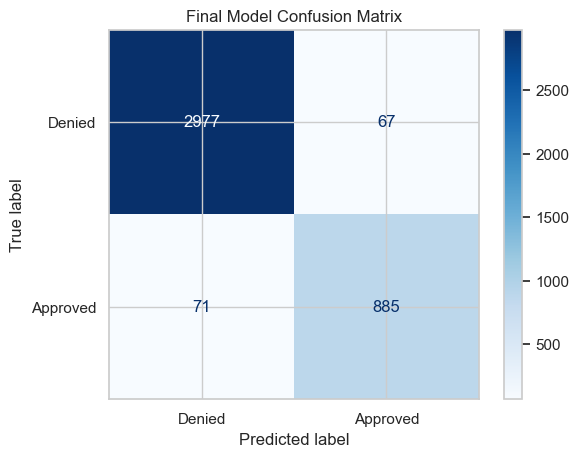

In [27]:

# Step 1: Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Step 2: Calculate final test metrics
final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

# Step 3: Display metrics in a table
metrics_df = pd.DataFrame(
    final_metrics.items(),
    columns=["Metric", "Score"]
)

display(metrics_df.round(4))

# Step 4: Display classification report
print(classification_report(y_test, y_pred))

# Step 5: Visualize confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Denied", "Approved"],
    cmap="Blues"
)

plt.title("Final Model Confusion Matrix")
plt.show()



## Final Conclusion and Recommendations

### Project Overview

This project developed a machine learning classification pipeline to predict historical loan approval decisions for FinTech Innovations.

The analysis followed the CRISP-DM framework, covering business understanding, data exploration, data preparation, modeling, optimization, and evaluation.

### Model Development

Five classification algorithms were compared:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Extra Trees
5. Gradient Boosting

Logistic Regression was selected based on cross-validation ROC-AUC.

### Hyperparameter Optimization

RandomizedSearchCV was applied using five-fold cross-validation.

The best hyperparameters were:

- C = 100
- class_weight = None

The optimized model achieved a cross-validation ROC-AUC of 0.9947.


### Final Test Performance

The optimized Logistic Regression model was evaluated
using 4,000 previously unseen test observations.

The model achieved:

- Accuracy: 96.55%
- Precision: 92.96%
- Recall: 92.57%
- F1-score: 92.77%
- ROC-AUC: 0.9946

These results demonstrate strong performance in
predicting historical loan approval decisions.

The model achieved high precision and recall,
indicating relatively few incorrect classifications.

However, these results do not establish the model's
ability to predict actual loan defaults.


### Business Impact

The business faces an estimated loss of $50,000 for approving a defaulting loan and $8,000 in missed profit for rejecting a creditworthy applicant.

An illustrative cost analysis was performed using the model's classification errors.

However, historical approval decisions do not directly establish whether an applicant would default or repay successfully. Consequently, the calculated costs should not be interpreted as actual lending losses.

### Model Limitations

The model may reproduce historical lending policies and any biases contained in previous approval decisions.

A high ROC-AUC does not guarantee that the model can predict loan defaults accurately.

Additional validation is required to investigate data leakage, fairness, model calibration, and performance across applicant groups.

### Recommendations

1. Use the model initially as a decision-support tool rather than an automated approval system.
2. Investigate the features most strongly associated with historical approval decisions.
3. Validate the model using actual repayment and default outcomes.
4. Assess model fairness across relevant applicant groups.
5. Monitor performance and retrain the model when necessary.


